# 01 – Données et features : Bitcoin (BTCUSDT), bougies de 8 h

**Objectif :** télécharger les bougies de **8 heures** du Bitcoin (**1 jour = 3 lignes** : 00h, 08h, 16h UTC), contrôler leur qualité, ne garder que les jours complets, construire les features, découper en train / test et sauvegarder ce dont le notebook HMM a besoin.

**Exécuter le notebook de haut en bas.** Chaque cellule de code est précédée d'une courte description.

| Étape | Cellules | Sortie |
|---|---|---|
| 1. Paramètres | 1–2 | bibliothèques, paramètres, contrôle de `src/fonctions.py` |
| 2. Téléchargement | 3 | `data/btcusdt_8h.csv` |
| 3. Qualité | 4–6 | tableau de contrôle, trous, jours complets (3 lignes / jour) |
| 4. Features | 7–10 | features, test ADF, corrélations |
| 5. Découpage, standardisation, sauvegarde | 11–14 | `data/btcusdt_features.csv`, `_X_train.csv`, `_X_test.csv`, `_scaler.joblib` |
| 6. Vérification | 15 | `TOUS LES CONTRÔLES SONT OK` |

## 1. Paramètres

### Cellule 1 – Bibliothèques et paramètres
Tous les paramètres sont **au même endroit** : actif, dates, fenêtres des indicateurs, jeu de features, proportion train / test.

Les fenêtres journalières sont multipliées par 3 (3 bougies par jour) : volatilité 20 jours → 60, RSI 14 jours → 42, MACD 12/26/9 → 36/78/27.

In [1]:
import sys, os, warnings
sys.path.append("../src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns, joblib
from statsmodels.tsa.stattools import adfuller
from sklearn.preprocessing import StandardScaler
from fonctions import *

warnings.filterwarnings("ignore", category=FutureWarning)

# --- données : Bitcoin uniquement, bougies de 8 h
SYMBOLE     = "BTCUSDT"
FICHIER     = "../data/btcusdt_8h.csv"
DEBUT, FIN  = "2017-08-17", "2026-11-01"     # période [DEBUT, FIN[
TELECHARGER = False                          # True = re-télécharger ; False = réutiliser data/btcusdt_8h.csv

# --- fenêtres des indicateurs (bougies de 8 h)
PAR_JOUR = 3                                 # 1 jour = 3 lignes
FEN_VOL, FEN_RSI, MACD = 60, 42, (36, 78, 27)

# --- jeu de features et découpage
JEUX = {"base":   ["rendement", "volatilite"],                      # jeu de base
        "etendu": ["rendement", "volatilite", "RSI", "vol_rel"]}    # jeu étendu
JEU = "base"                                                        # "base" ou "etendu"
CHOIX = JEUX[JEU]
TRAIN_FRAC = 0.7                                                    # découpage chronologique, sans mélange

for dossier in ("../data", "../results"):
    os.makedirs(dossier, exist_ok=True)
print("Jeu de features :", JEU, CHOIX)

Jeu de features : base ['rendement', 'volatilite']


### Cellule 2 – Contrôle de `src/fonctions.py`
S'arrête avec un **message clair** s'il manque une fonction (cause typique : ancien `fonctions.py`, ou noyau non redémarré après modification).

In [2]:
requises = ["charger_binance", "garder_jours_complets", "calculer_rendement_log",
            "calculer_volatilite", "calculer_RSI", "calculer_MACD", "construire_features"]
manquantes = [f for f in requises if f not in globals()]
assert not manquantes, (f"Manquant dans src/fonctions.py : {manquantes}. "
                        "Mettre à jour src/fonctions.py puis Kernel > Restart.")
print("fonctions.py OK")

fonctions.py OK


## 2. Téléchargement

### Cellule 3 – Bougies de 8 h du Bitcoin
API publique Binance (1000 bougies par requête, avec pagination), prix en USDT, heures en UTC. Avec `TELECHARGER = False`, le fichier existant est réutilisé.

In [3]:
if TELECHARGER or not os.path.exists(FICHIER):
    brut = charger_binance(SYMBOLE, "8h", DEBUT, FIN)
    brut.to_csv(FICHIER)
    etat = "téléchargé"
else:
    brut = pd.read_csv(FICHIER, index_col=0, parse_dates=True)
    etat = "réutilisé"
brut = brut.sort_index()
print(f"{SYMBOLE} {etat} : {brut.shape[0]} lignes, du {brut.index[0]} au {brut.index[-1]}")

BTCUSDT réutilisé : 10087 lignes, du 2017-08-17 00:00:00 au 2026-11-01 00:00:00


## 3. Contrôle qualité

### Cellule 4 – Tableau de contrôle
Nombre de lignes, dates, doublons, valeurs manquantes, volumes nuls, heures des bougies, et **nombre de lignes par jour** (on attend 3).

In [4]:
par_jour = brut.groupby(brut.index.normalize()).size()
pd.Series({"lignes": len(brut), "début": brut.index[0], "fin": brut.index[-1],
           "doublons": int(brut.index.duplicated().sum()), "NaN": int(brut.isna().sum().sum()),
           "volume nul": int((brut["Volume"] == 0).sum()),
           "heures des bougies": sorted(brut.index.hour.unique()),
           "jours": len(par_jour), "jours à 3 lignes": int((par_jour == 3).sum()),
           "jours incomplets": int((par_jour != 3).sum())}).to_frame("BTCUSDT 8h")

,BTCUSDT 8h
lignes,10087
début,2017-08-17 00:00:00
fin,2026-11-01 00:00:00
doublons,0
NaN,0
volume nul,0
heures des bougies,"[0, 8, 16]"
jours,3364
jours à 3 lignes,3361
jours incomplets,3


### Cellule 5 – Où sont les trous ?
Un trou = un pas de temps supérieur à 8 h. Les jours incomplets correspondent à une panne de Binance (février 2018) et, éventuellement, à un dernier jour tronqué.

In [5]:
pas = brut.index.to_series().diff()
trous = pas[pas > pd.Timedelta("8h")]
display(pd.DataFrame({"bougie après le trou": trous.index, "trou": trous.values,
                      "bougies manquantes": (trous / pd.Timedelta("8h") - 1).round().astype(int).values}))
print("Jours incomplets :")
print(par_jour[par_jour != 3].to_string())

,bougie après le trou,trou,bougies manquantes
0,2018-02-09 08:00:00,1 days 08:00:00,3


Jours incomplets :
Date
2018-02-08    1
2018-02-09    2
2026-11-01    1


### Cellule 6 – Garder uniquement les jours complets (1 jour = 3 lignes)
`garder_jours_complets` supprime les jours qui n'ont pas exactement 3 bougies. On perd une poignée de lignes, mais chaque jour du jeu de données a désormais la même structure (00h, 08h, 16h).

In [6]:
df = garder_jours_complets(brut, PAR_JOUR)
nb_par_jour = df.groupby(df.index.normalize()).size()
assert (nb_par_jour == 3).all(), "il reste des jours incomplets"
assert len(df) % 3 == 0 and (df.index.hour.values.reshape(-1, 3) == [0, 8, 16]).all()
print(f"Lignes : {len(brut)} -> {len(df)} ({len(brut) - len(df)} supprimées) | {len(nb_par_jour)} jours x 3 lignes")

Lignes : 10087 -> 10083 (4 supprimées) | 3361 jours x 3 lignes


## 4. Features

### Cellule 7 – Effet de session sur le volume (justifie `vol_rel`)
Les bougies de 00h, 08h et 16h n'ont pas le même volume. Une simple variation de volume mesure donc surtout *quelle bougie de la journée c'est*. `vol_rel` compare chaque bougie au volume moyen de **la même session sur les 20 derniers jours** (passé uniquement).

Lecture : la première colonne montre un effet de session net ; la seconde doit être **à peu près égale** entre les sessions.

In [7]:
h = df.index.hour
dv = np.log1p(df["Volume"]).diff()
v_session = df["Volume"].groupby(h).transform(lambda s: s.rolling(20).mean().shift(1))
vol_rel = np.log(df["Volume"] / v_session).replace([np.inf, -np.inf], np.nan)

pd.DataFrame({"variation moyenne du log-volume": dv.groupby(h).mean(),
              "vol_rel moyen (utilisé)": vol_rel.groupby(h).mean()}).rename_axis("session (h UTC)").round(2)

,variation moyenne du log-volume,vol_rel moyen (utilisé)
session (h UTC),,
0,-0.12,-0.11
8,0.30,-0.10
16,-0.18,-0.11


### Cellule 8 – Calcul des features
`construire_features` (dans `src/fonctions.py`) : `rendement` (log), `volatilite` (écart-type glissant, 60 bougies), `RSI` (42), `MACD_norm` et `histo_norm` (MACD / prix), `amplitude` ((High−Low)/Close), `vol_rel`. Les premières lignes ont des `NaN` à cause des fenêtres glissantes : elles sont supprimées, ainsi que le premier jour s'il devient incomplet.

In [8]:
feat = construire_features(df, FEN_VOL, FEN_RSI, MACD)
print("NaN créés par les fenêtres :")
print(feat.isna().sum().to_string())
feat = garder_jours_complets(feat.dropna(), PAR_JOUR)
print("\nLignes gardées :", len(feat), "sur", len(df), f"({len(feat) // 3} jours complets)")
feat.describe().T.round(4)

NaN créés par les fenêtres :
rendement      1
volatilite    60
RSI           42
MACD_norm      0
histo_norm     0
amplitude      0
vol_rel       60

Lignes gardées : 10023 sur 10083 (3341 jours complets)


,count,mean,std,min,25%,50%,75%,max
rendement,10023.0,0.0003,0.0200,-0.2449,-0.0070,0.0004,0.0078,0.1961
volatilite,10023.0,0.0179,0.0091,0.0041,0.0118,0.0158,0.0210,0.0576
RSI,10023.0,51.4594,8.6684,20.1020,45.8372,50.5259,56.9756,81.3347
MACD_norm,10023.0,0.0012,0.0427,-0.2187,-0.0192,0.0019,0.0271,0.1439
histo_norm,10023.0,0.0001,0.0129,-0.0875,-0.0064,0.0004,0.0078,0.0459
amplitude,10023.0,0.0276,0.0238,0.0015,0.0134,0.0211,0.0336,0.3792
vol_rel,10023.0,-0.1070,0.5413,-2.6287,-0.4222,-0.1115,0.2141,2.4597


### Cellule 9 – Test de stationnarité (ADF)
Test de Dickey-Fuller augmenté sur chaque feature. **p < 0,05 → stationnaire** (pas de racine unitaire) : c'est pourquoi on modélise les rendements et non les prix. Remarque : l'ADF ne dit pas que la *variance* est constante ; les grappes de volatilité restent, et c'est justement ce que capte le HMM.

In [9]:
res = []
for c in feat.columns:
    p = adfuller(feat[c], autolag="AIC")[1]
    res.append({"variable": c, "p_value": p, "stationnaire (p<0,05)": p < 0.05})
pd.DataFrame(res).style.format({"p_value": "{:.2e}"})

,variable,p_value,"stationnaire (p<0,05)"
0,rendement,0.00e+00,True
1,volatilite,2.09e-07,True
2,RSI,1.31e-13,True
3,MACD_norm,3.49e-12,True
4,histo_norm,2.62e-28,True
5,amplitude,3.37e-12,True
6,vol_rel,2.16e-27,True


### Cellule 10 – Corrélation entre features
Heatmap + liste des paires avec |corrélation| > 0,7. Deux features presque identiques rendent un HMM à covariance pleine instable : on n'en garde **qu'une** par paire. Sauvegardé dans `results/correlation_features.png`.

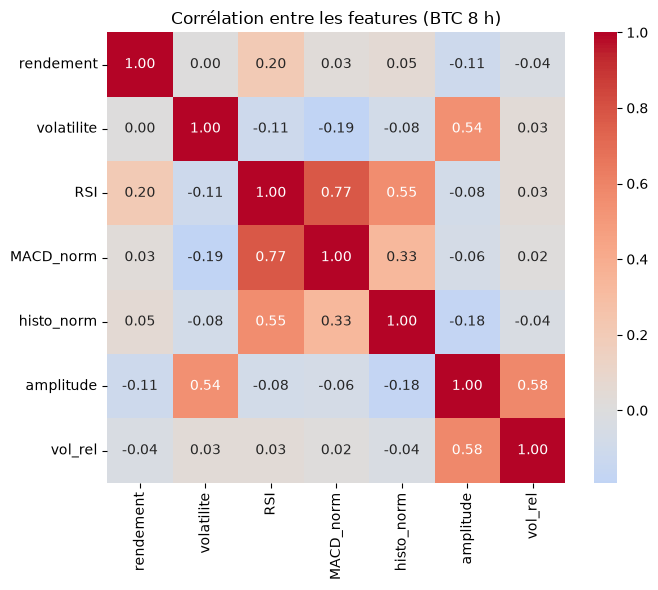

Paires avec |corr| > 0,7 : [('RSI', 'MACD_norm', np.float64(0.77))]


In [10]:
corr = feat.corr()
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Corrélation entre les features (BTC 8 h)")
plt.tight_layout()
plt.savefig("../results/correlation_features.png", dpi=150)
plt.show()

forts = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(corr.columns)
         for b in corr.columns[i+1:] if abs(corr.loc[a, b]) > 0.7]
print("Paires avec |corr| > 0,7 :", forts)

## 5. Découpage, standardisation et sauvegarde

### Cellule 11 – Découpage chronologique sur des jours entiers
Les premiers 70 % des **jours** vont dans le train, les derniers 30 % dans le test : la coupure tombe entre la bougie de 16h et celle de 00h, jamais au milieu d'une journée. Le `StandardScaler` est ajusté **sur le train uniquement** (pas de look-ahead).

In [11]:
X = feat[CHOIX]
k = int(len(X) // PAR_JOUR * TRAIN_FRAC) * PAR_JOUR          # coupure sur un nombre entier de jours
scaler  = StandardScaler().fit(X.iloc[:k])                    # ajusté sur le TRAIN seulement
X_train = pd.DataFrame(scaler.transform(X.iloc[:k]), index=X.index[:k], columns=CHOIX)
X_test  = pd.DataFrame(scaler.transform(X.iloc[k:]), index=X.index[k:], columns=CHOIX)

print("train :", X_train.index[0], "->", X_train.index[-1], f"({len(X_train)} lignes = {len(X_train) // 3} jours)")
print("test  :", X_test.index[0],  "->", X_test.index[-1],  f"({len(X_test)} lignes = {len(X_test) // 3} jours)")

train : 2017-09-06 00:00:00 -> 2024-02-01 16:00:00 (7014 lignes = 2338 jours)
test  : 2024-02-02 00:00:00 -> 2026-10-31 16:00:00 (3009 lignes = 1003 jours)


### Cellule 12 – Comparaison train / test
La moyenne du train vaut ≈ 0 par construction. Une moyenne du test **différente de 0** est normale et informative : elle indique à quel point la période de test diffère de la période d'apprentissage (par exemple un marché plus calme).

In [12]:
pd.DataFrame({"moyenne train": X_train.mean(), "moyenne test": X_test.mean(),
              "écart-type train": X_train.std(), "écart-type test": X_test.std()}).round(2)

,moyenne train,moyenne test,écart-type train,écart-type test
rendement,-0.0,-0.01,1.0,0.61
volatilite,-0.0,-0.69,1.0,0.37


### Cellule 13 – Graphique des features et du découpage
Rendement, volatilité et volume relatif dans le temps, avec une ligne verticale au début du test. Sauvegardé dans `results/features_btc.png` (utile pour le rapport).

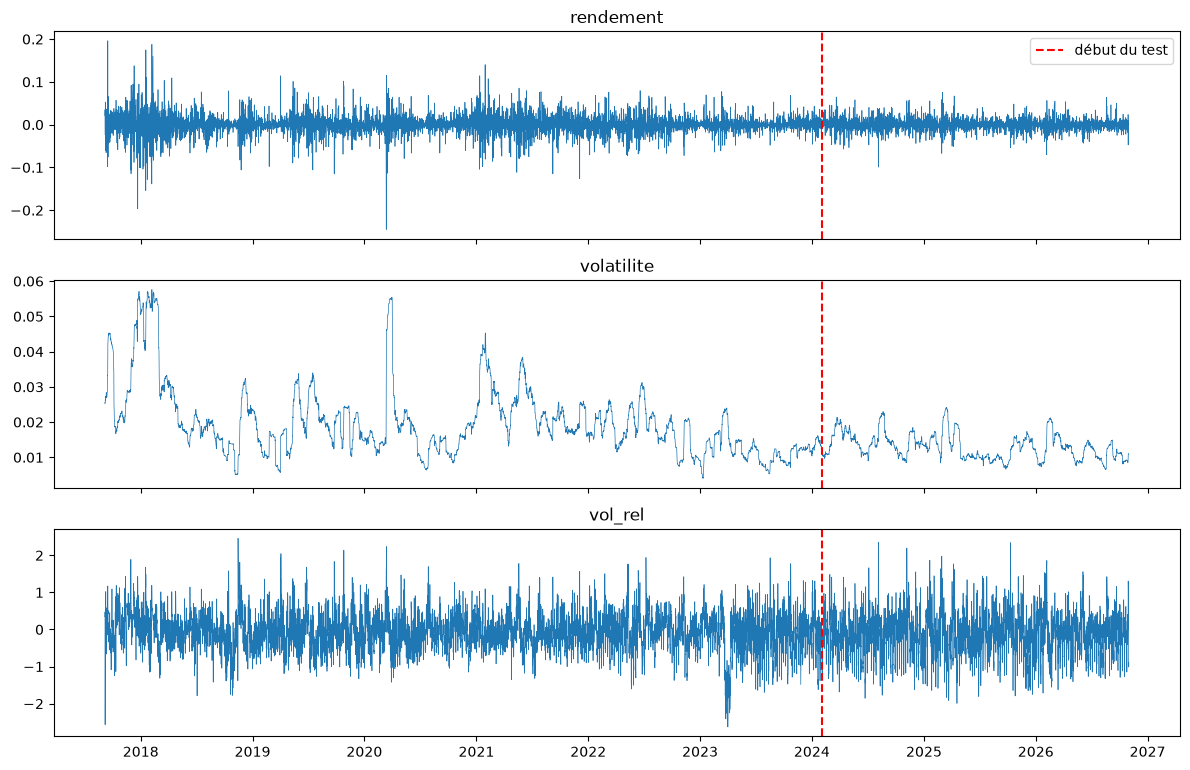

In [13]:
cols = ["rendement", "volatilite", "vol_rel"]
fig, axes = plt.subplots(len(cols), 1, figsize=(12, 2.6 * len(cols)), sharex=True)
for ax, c in zip(axes, cols):
    ax.plot(feat.index, feat[c], lw=0.5)
    ax.axvline(X_test.index[0], color="red", ls="--", label="début du test")
    ax.set_title(c)
axes[0].legend()
plt.tight_layout()
plt.savefig("../results/features_btc.png", dpi=150)
plt.show()

### Cellule 14 – Sauvegarde
Écrit `data/btcusdt_features.csv` (toutes les features + `Close`), `_X_train.csv`, `_X_test.csv` et `_scaler.joblib` (pour réutiliser la même standardisation, par exemple dans le dashboard).

In [14]:
feat.join(df["Close"]).to_csv("../data/btcusdt_features.csv")
X_train.to_csv("../data/btcusdt_X_train.csv")
X_test.to_csv("../data/btcusdt_X_test.csv")
joblib.dump(scaler, "../data/btcusdt_scaler.joblib")
print("Fichiers sauvegardés dans data/")

Fichiers sauvegardés dans data/


## 6. Vérification finale

### Cellule 15 – Contrôle automatique des fichiers sauvegardés
Recharge les fichiers et vérifie : pas de `NaN`, mêmes colonnes que le jeu choisi et que le scaler, dates croissantes, **le test commence après la fin du train**, et **chaque jour a exactement 3 lignes**.

In [15]:
Xtr = pd.read_csv("../data/btcusdt_X_train.csv", index_col=0, parse_dates=True)
Xte = pd.read_csv("../data/btcusdt_X_test.csv",  index_col=0, parse_dates=True)
ft  = pd.read_csv("../data/btcusdt_features.csv", index_col=0, parse_dates=True)
sc  = joblib.load("../data/btcusdt_scaler.joblib")

assert not Xtr.isna().any().any() and not Xte.isna().any().any(), "NaN dans les fichiers X"
assert list(Xtr.columns) == CHOIX == list(sc.feature_names_in_), "colonnes différentes du jeu choisi"
assert Xtr.index.is_monotonic_increasing and Xte.index.is_monotonic_increasing, "dates non triées"
assert Xtr.index[-1] < Xte.index[0], "le test doit commencer après le train"
assert set(CHOIX) <= set(ft.columns) and "Close" in ft.columns, "fichier de features incomplet"
for nom, t in [("train", Xtr), ("test", Xte), ("features", ft)]:
    assert (t.groupby(t.index.normalize()).size() == 3).all(), f"{nom} : un jour n'a pas 3 lignes"
print("TOUS LES CONTRÔLES SONT OK |", len(Xtr), "lignes train,", len(Xte), "lignes test | features :", CHOIX)

TOUS LES CONTRÔLES SONT OK | 7014 lignes train, 3009 lignes test | features : ['rendement', 'volatilite']


## Étape suivante
Notebook `03_hmm_rendements` : entraîner le HMM sur `data/btcusdt_X_train.csv` (N = 2 à 5, AIC/BIC, plusieurs initialisations), interpréter les régimes, puis prédire le régime suivant avec le filtre forward (sans look-ahead).